In [ ]:
!pip install pywavelets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 8.8 MB/s eta 0:00:00


In [25]:
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
max([10,200])

200

## Creación de la señal

In [27]:
F1 = 20 #hz
F2 = 100 #hz

Fmax = lambda f1_,f2_: max([f1_, f2_])

Fs = 10*Fmax(F1,F2)
Ts = 1/Fs

print(f"Frecuencia 1: {F1} hz")
print(f"Frecuencia 2: {F2} hz")
print(f"Frecuencia max: {Fmax(F1,F2)} hz")
print(f"Frecuencia de muestreo 10*Fmax: {Fs} M/s")

Frecuencia 1: 20 hz
Frecuencia 2: 100 hz
Frecuencia max: 100 hz
Frecuencia de muestreo 10*Fmax: 1000 M/s


In [28]:
n = np.arange(0,1000)
t = n*Ts

In [29]:
x1 = 10*np.sin(2*np.pi*F1*t)
x2 = 10*np.sin(2*np.pi*F2*t)
x3 = x1+x2

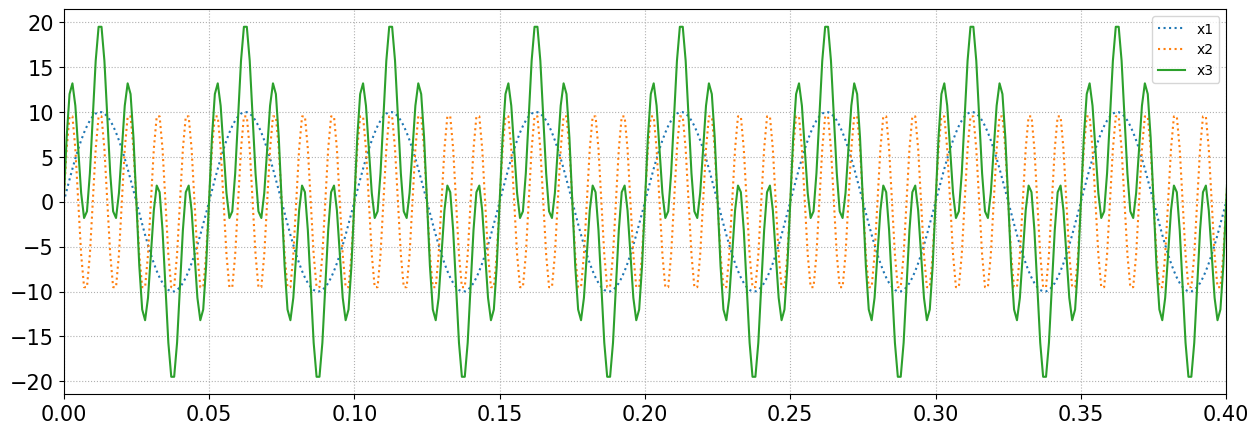

In [46]:
plt.figure(figsize=(15,5))
plt.plot(t,x1,label="x1", linestyle=":")
plt.plot(t,x2,label="x2", linestyle=":")
plt.plot(t,x3,label="x3")
plt.legend()
plt.grid(ls=":")
plt.xlim(0,0.4)
plt.show()

## Mostrar FFT

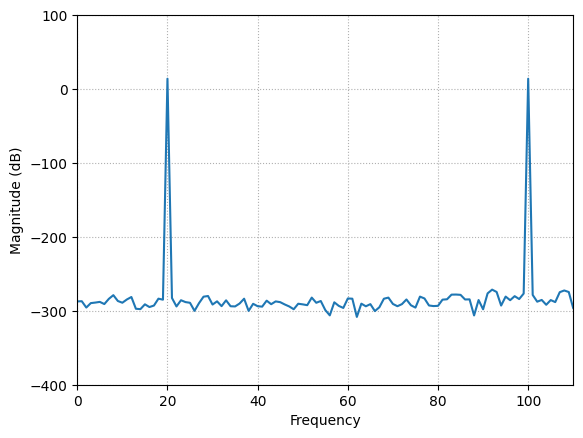

In [40]:
plt.magnitude_spectrum(x3, Fs=Fs, window=np.ones(x3.shape),scale="dB")# , sides='twosided')
plt.xlim(0,110)
plt.ylim(-400,100)
plt.grid(ls=":")
plt.show()

## Filtrado por wavelets

### Single-level Wavelet Decomposition


#####  1D single-level DWT


In [41]:
(cA,cD) = pywt.dwt(x3,'db2','sym')

In [43]:
print('Length of orignal signal: ',len(x3))
print('Length of Approximation Coefficient: ', len(cA))
print('Length of Detail Coefficient: ',len(cD))

Length of orignal signal:  1000
Length of Approximation Coefficient:  501
Length of Detail Coefficient:  501


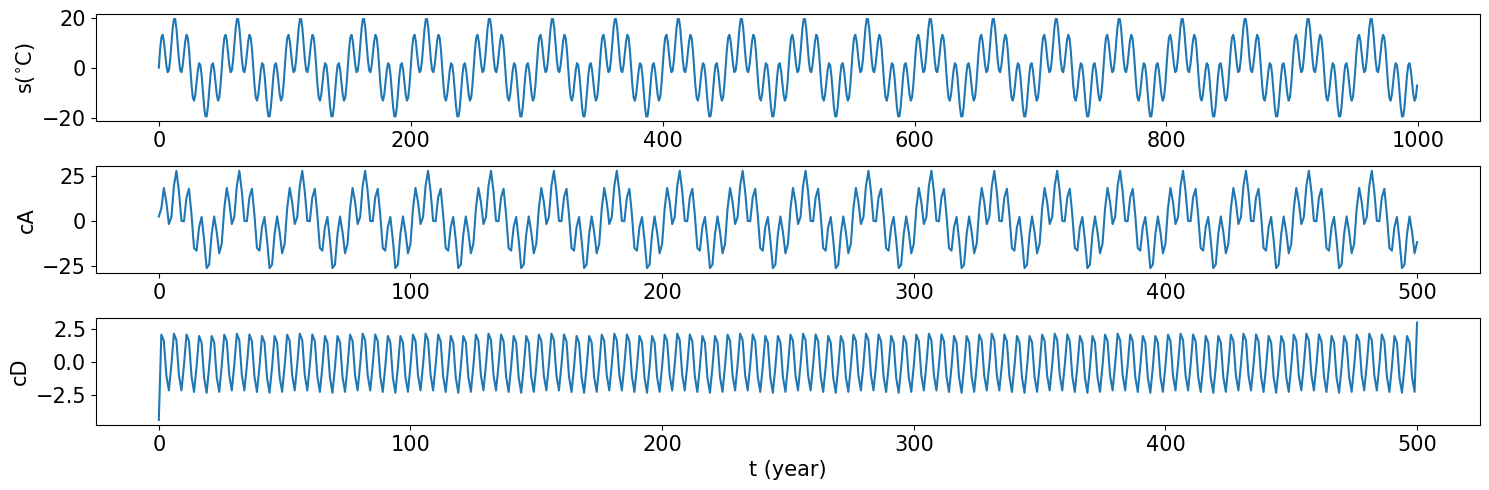

In [51]:
# Reconstruct the Signal, inverse discrete wavelet transform

fig,axs = plt.subplots(3,1,figsize=(15,5))
plt.rc('xtick',labelsize=15)
plt.rc('ytick',labelsize=15)
axs[0].plot(x3)
axs[0].set_ylabel('s($^{\circ}$C)',fontsize=15)
axs[1].plot(cA)
axs[1].set_ylabel('cA',fontsize=15)
axs[2].plot(cD)
axs[2].set_ylabel('cD',fontsize=15)
axs[2].set_xlabel('t (year)',fontsize=15)

plt.tight_layout()
plt.show()

#### . Reconstruct the Signal

In [52]:
s_r = pywt.idwt(cA,cD,'db2','sym')

In [59]:
print('Length of orignial signal: ',len(x3))
print('Length of reconstructed signal: ',len(s_r))

Length of orignial signal:  1000
Length of reconstructed signal:  998


In [56]:
s_r = s_r[:-1]

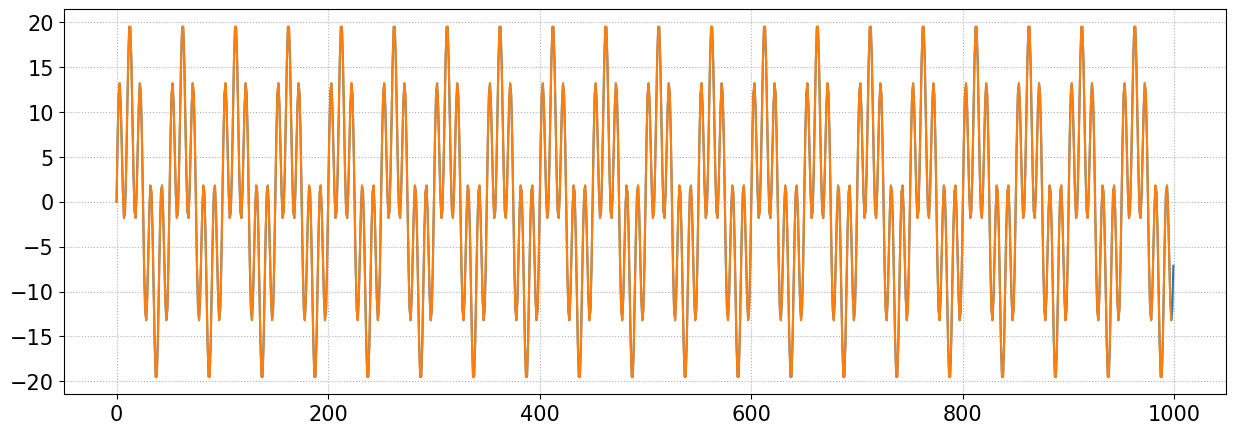

In [60]:
plt.figure(figsize=(15,5))
plt.plot(x3)
plt.plot(s_r)
plt.grid(ls=":")

#### Partial Wavelet Reconstruction

##### Methodo 1

In [67]:
# Method 1: upcoef method

A = pywt.upcoef('a',cA,'db2',level=1,take=len(x3))
D = pywt.upcoef('d',cD,'db2',level=1,take=len(x3))

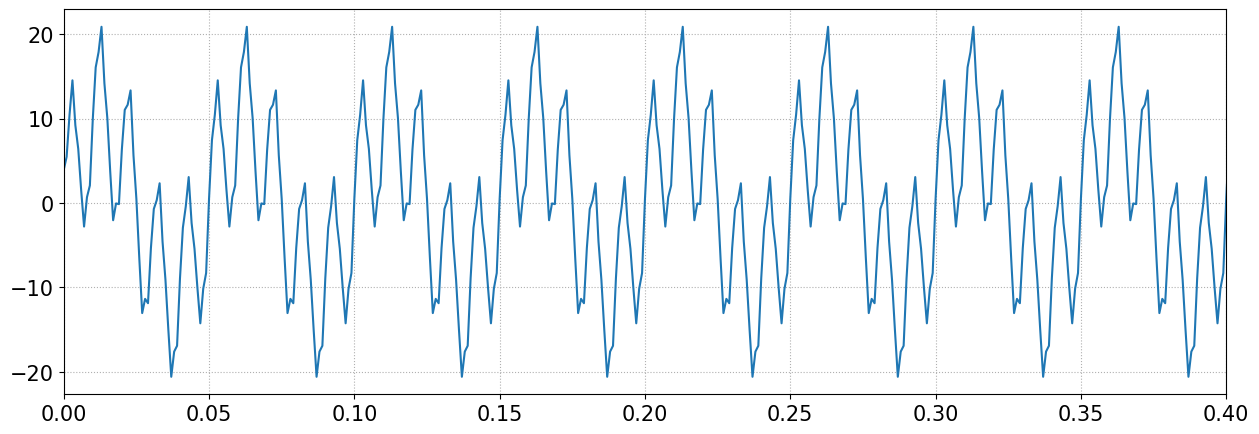

In [86]:
plt.figure(figsize=(15,5))
plt.plot(t[:-1],A)
plt.grid(ls=":")
plt.xlim(0,0.4)
plt.show()

In [69]:
# Reconstruct signal from the approximation and details
# from method 1
s_r = A + D
print(len(x3))
print(len(s_r))



1000
1000


##### Methodo 2

In [68]:
# Method 2: inverse discrete wavelet transform

A1 = pywt.idwt(cA, None,'db2','sym')
D1 = pywt.idwt(None, cD, 'db2','sym')

In [70]:
#  from method 2
s1_r = A1 + D1
print(len(s1_r))


1000


In [71]:
s1_r = s1_r[:-1]

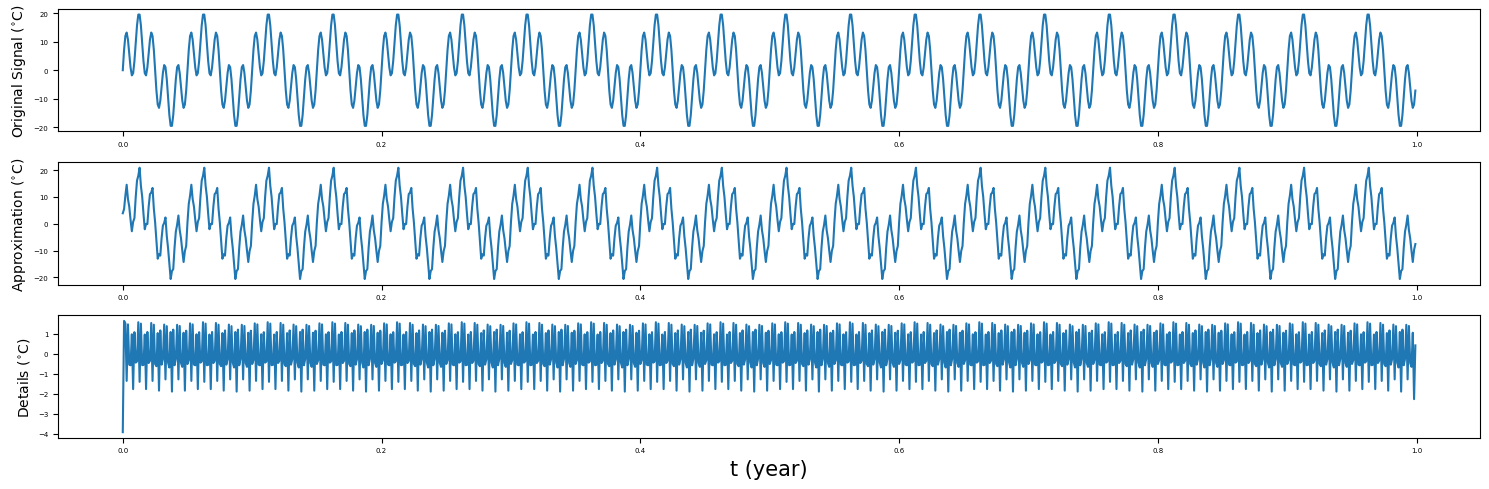

In [75]:
# Visualization of Signal Approximation and Details

fig,(ax1,ax2,ax3) = plt.subplots(3,1,figsize=(15,5))
plt.rc('xtick',labelsize=5)
plt.rc('ytick',labelsize=5)
ax1.plot(t,x3)
ax1.set_ylabel('Original Signal ($^{\circ}$C)',fontsize=10)
ax2.plot(t,A)
ax2.set_ylabel('Approximation ($^{\circ}$C)',fontsize=10)
ax3.plot(t,D)
ax3.set_ylabel('Details ($^{\circ}$C)',fontsize=10)
ax3.set_xlabel('t (year)',fontsize=15)
plt.tight_layout()
plt.show()

### Noise Reduction

Detail constinuent is the high frequency data, which can be removed as noise.

- just keep the Approximation constituent
- just reconstruct the Approximation constituent


In [ ]:
A = pywt.upcoef('a',cA,'db2',level=1,take=len(s))


In [76]:
A = pywt.idwt(cA, None,'db2','sym')
A = A[:-1]

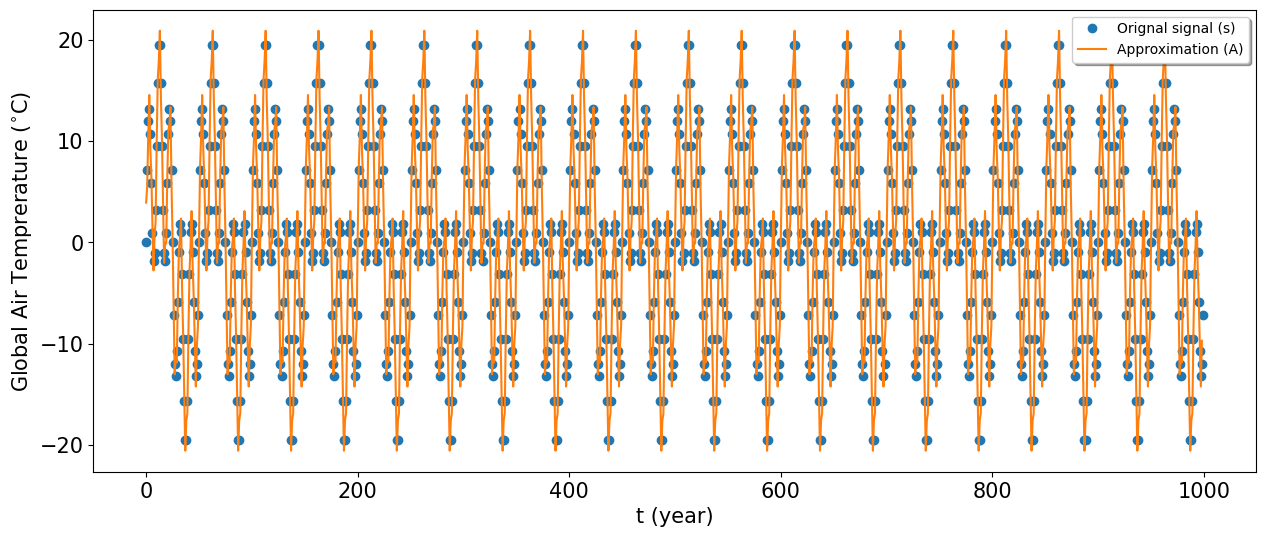

In [78]:
fig,ax = plt.subplots(figsize=(15,6))
plt.rc('xtick',labelsize=15)
plt.rc('ytick',labelsize=15)
ax.plot(x3,'o')
ax.plot(A)
ax.set_ylabel('Global Air Temprerature ($^{\circ}$C)',fontsize=15)
ax.set_xlabel('t (year)',fontsize=15)
ax.legend(('Orignal signal (s)','Approximation (A)'),loc='best',shadow=True)

plt.show()